# Predicting Heart Attack Chance

## Pakcages & Libs

In [208]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn import preprocessing
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn import svm
from sklearn.metrics import classification_report
from sklearn.metrics import accuracy_score, fbeta_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

In [209]:
import warnings
warnings.filterwarnings('ignore')

### Reading Data

#### **Chance Of Heart Attack (Output)**: 
- 0: low Chance
- 1: High Chance

In [210]:
df = pd.read_csv("16325569497737558.csv")
df.head()

,age,sex,cp,trtbps,chol,fbs,restecg,thalachh,exng,oldpeak,slp,caa,thall,output
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [211]:
df.describe()

,age,sex,cp,trtbps,chol,fbs,restecg,thalachh,exng,oldpeak,slp,caa,thall,output
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000
mean,54.366337,0.683168,0.966997,131.623762,246.264026,0.148515,0.528053,149.646865,0.326733,1.039604,1.399340,0.729373,2.313531,0.544554
std,9.082101,0.466011,1.032052,17.538143,51.830751,0.356198,0.525860,22.905161,0.469794,1.161075,0.616226,1.022606,0.612277,0.498835
min,29.000000,0.000000,0.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,47.500000,0.000000,0.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,55.000000,1.000000,1.000000,130.000000,240.000000,0.000000,1.000000,153.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,274.500000,0.000000,1.000000,166.000000,1.000000,1.600000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


## Pre-processing

In [212]:
X = np.asarray(df.iloc[:, :-1])
X[:5]

array([[ 63. ,   1. ,   3. , 145. , 233. ,   1. ,   0. , 150. ,   0. ,
          2.3,   0. ,   0. ,   1. ],
       [ 37. ,   1. ,   2. , 130. , 250. ,   0. ,   1. , 187. ,   0. ,
          3.5,   0. ,   0. ,   2. ],
       [ 41. ,   0. ,   1. , 130. , 204. ,   0. ,   0. , 172. ,   0. ,
          1.4,   2. ,   0. ,   2. ],
       [ 56. ,   1. ,   1. , 120. , 236. ,   0. ,   1. , 178. ,   0. ,
          0.8,   2. ,   0. ,   2. ],
       [ 57. ,   0. ,   0. , 120. , 354. ,   0. ,   1. , 163. ,   1. ,
          0.6,   2. ,   0. ,   2. ]])

In [213]:
y = np.asarray(df[["output"]])
y[:5]

array([[1],
       [1],
       [1],
       [1],
       [1]], dtype=int64)

Normilizing X values for Logistic Regression

In [214]:
X_LR = preprocessing.StandardScaler().fit(X).transform(X)
X_LR[0:5]

array([[ 0.9521966 ,  0.68100522,  1.97312292,  0.76395577, -0.25633371,
         2.394438  , -1.00583187,  0.01544279, -0.69663055,  1.08733806,
        -2.27457861, -0.71442887, -2.14887271],
       [-1.91531289,  0.68100522,  1.00257707, -0.09273778,  0.07219949,
        -0.41763453,  0.89896224,  1.63347147, -0.69663055,  2.12257273,
        -2.27457861, -0.71442887, -0.51292188],
       [-1.47415758, -1.46841752,  0.03203122, -0.09273778, -0.81677269,
        -0.41763453, -1.00583187,  0.97751389, -0.69663055,  0.31091206,
         0.97635214, -0.71442887, -0.51292188],
       [ 0.18017482,  0.68100522,  0.03203122, -0.66386682, -0.19835726,
        -0.41763453,  0.89896224,  1.23989692, -0.69663055, -0.20670527,
         0.97635214, -0.71442887, -0.51292188],
       [ 0.29046364, -1.46841752, -0.93851463, -0.66386682,  2.08204965,
        -0.41763453,  0.89896224,  0.58393935,  1.43548113, -0.37924438,
         0.97635214, -0.71442887, -0.51292188]])

## Creating Train & Test  

Train & Test for Decision Tree Modeling

In [215]:
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=2)
x_train[:5]

array([[6.00e+01, 1.00e+00, 0.00e+00, 1.40e+02, 2.93e+02, 0.00e+00,
        0.00e+00, 1.70e+02, 0.00e+00, 1.20e+00, 1.00e+00, 2.00e+00,
        3.00e+00],
       [6.90e+01, 1.00e+00, 3.00e+00, 1.60e+02, 2.34e+02, 1.00e+00,
        0.00e+00, 1.31e+02, 0.00e+00, 1.00e-01, 1.00e+00, 1.00e+00,
        2.00e+00],
       [5.40e+01, 1.00e+00, 0.00e+00, 1.40e+02, 2.39e+02, 0.00e+00,
        1.00e+00, 1.60e+02, 0.00e+00, 1.20e+00, 2.00e+00, 0.00e+00,
        2.00e+00],
       [6.60e+01, 0.00e+00, 2.00e+00, 1.46e+02, 2.78e+02, 0.00e+00,
        0.00e+00, 1.52e+02, 0.00e+00, 0.00e+00, 1.00e+00, 1.00e+00,
        2.00e+00],
       [5.90e+01, 1.00e+00, 1.00e+00, 1.40e+02, 2.21e+02, 0.00e+00,
        1.00e+00, 1.64e+02, 1.00e+00, 0.00e+00, 2.00e+00, 0.00e+00,
        2.00e+00]])

In [216]:
x_test[:5]

array([[ 53. ,   1. ,   2. , 130. , 246. ,   1. ,   0. , 173. ,   0. ,
          0. ,   2. ,   3. ,   2. ],
       [ 63. ,   0. ,   0. , 124. , 197. ,   0. ,   1. , 136. ,   1. ,
          0. ,   1. ,   0. ,   2. ],
       [ 58. ,   0. ,   0. , 100. , 248. ,   0. ,   0. , 122. ,   0. ,
          1. ,   1. ,   0. ,   2. ],
       [ 41. ,   0. ,   1. , 105. , 198. ,   0. ,   1. , 168. ,   0. ,
          0. ,   2. ,   1. ,   2. ],
       [ 70. ,   1. ,   0. , 130. , 322. ,   0. ,   0. , 109. ,   0. ,
          2.4,   1. ,   3. ,   2. ]])

Train & Test for Logistic Regression Modeling

In [217]:
x_train_, x_test_, y_train_, y_test_ = train_test_split(X_LR, y, test_size=0.2, random_state=2)
x_train_[:5]

array([[ 0.62133012,  0.68100522, -0.93851463,  0.47839125,  0.90319523,
        -0.41763453, -1.00583187,  0.89005288, -0.69663055,  0.13837295,
        -0.64911323,  1.24459328,  1.12302895],
       [ 1.61392956,  0.68100522,  1.97312292,  1.62064933, -0.23700823,
         2.394438  , -1.00583187, -0.81543681, -0.69663055, -0.81059216,
        -0.64911323,  0.26508221, -0.51292188],
       [-0.04040284,  0.68100522, -0.93851463,  0.47839125, -0.14038081,
        -0.41763453,  0.89896224,  0.45274783, -0.69663055,  0.13837295,
         0.97635214, -0.71442887, -0.51292188],
       [ 1.28306308, -1.46841752,  1.00257707,  0.82106867,  0.613313  ,
        -0.41763453, -1.00583187,  0.1029038 , -0.69663055, -0.89686172,
        -0.64911323,  0.26508221, -0.51292188],
       [ 0.5110413 ,  0.68100522,  0.03203122,  0.47839125, -0.4882395 ,
        -0.41763453,  0.89896224,  0.62766985,  1.43548113, -0.89686172,
         0.97635214, -0.71442887, -0.51292188]])

## Decision Tree Modeling

Criterion: gini

In [218]:
gini_tree = DecisionTreeClassifier(criterion="gini")
gini_tree.fit(x_train, y_train)
gini_tree

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


Criterion: entropy

In [219]:
entropy_tree = DecisionTreeClassifier(criterion="entropy")
entropy_tree.fit(x_train, y_train)
entropy_tree

,criterion,'entropy'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


Criterion: log_loss

In [220]:
log_loss_tree = DecisionTreeClassifier(criterion="log_loss")
log_loss_tree.fit(x_train, y_train)
log_loss_tree

,criterion,'log_loss'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


## Decision Tree Evaluation

In [221]:
y_pred_gini = gini_tree.predict(x_test)
y_pred_entropy = entropy_tree.predict(x_test)
y_pred_log_loss = log_loss_tree.predict(x_test)

print(classification_report(y_test, y_pred_gini))
print("    f2-score       %.2f" % fbeta_score(y_test, y_pred_gini, beta=0.5))
print(classification_report(y_test, y_pred_entropy))
print("    f2-score       %.2f" % fbeta_score(y_test, y_pred_entropy, beta=0.5))
print(classification_report(y_test, y_pred_log_loss))
print("    f2-score       %.2f" % fbeta_score(y_test, y_pred_log_loss, beta=0.5))

              precision    recall  f1-score   support

           0       0.93      0.78      0.85        32
           1       0.79      0.93      0.86        29

    accuracy                           0.85        61
   macro avg       0.86      0.86      0.85        61
weighted avg       0.86      0.85      0.85        61

    f2-score       0.82
              precision    recall  f1-score   support

           0       0.92      0.69      0.79        32
           1       0.73      0.93      0.82        29

    accuracy                           0.80        61
   macro avg       0.82      0.81      0.80        61
weighted avg       0.83      0.80      0.80        61

    f2-score       0.76
              precision    recall  f1-score   support

           0       0.92      0.69      0.79        32
           1       0.73      0.93      0.82        29

    accuracy                           0.80        61
   macro avg       0.82      0.81      0.80        61
weighted avg       0.83   

In conclusion, Decision Tree with gini criterion has better accuracy.

## Logistic Regression Modeling
### Logistic Regression Evaluation
c = 0.01 ... 0.09

In [222]:
c_range = np.arange(0.01, 0.1, 0.01)

for c in c_range:
    LR = LogisticRegression(C=c, solver="liblinear")
    LR.fit(x_train_, y_train_)

    y_hat = LR.predict(x_test_)
    acc = accuracy_score(y_test_, y_hat)
    f2 = fbeta_score(y_test_, y_hat, beta=0.5)
    print(f"C: {c}, Accuracy: {acc}, R2-Score: {f2}")

C: 0.01, Accuracy: 0.9016393442622951, R2-Score: 0.8695652173913043
C: 0.02, Accuracy: 0.8688524590163934, R2-Score: 0.8284023668639053
C: 0.03, Accuracy: 0.8688524590163934, R2-Score: 0.8284023668639053
C: 0.04, Accuracy: 0.8688524590163934, R2-Score: 0.8284023668639053
C: 0.05, Accuracy: 0.8688524590163934, R2-Score: 0.8284023668639053
C: 0.060000000000000005, Accuracy: 0.8688524590163934, R2-Score: 0.8284023668639053
C: 0.06999999999999999, Accuracy: 0.8688524590163934, R2-Score: 0.8284023668639053
C: 0.08, Accuracy: 0.8688524590163934, R2-Score: 0.8284023668639053
C: 0.09, Accuracy: 0.8688524590163934, R2-Score: 0.8284023668639053


In conclusion, Lodistic Regression model with c = 0.01 has better accuracy and r2-score than Decision Tree.

In [223]:
LR = LogisticRegression(C=0.01, solver="liblinear")
LR.fit(x_train_, y_train_)
y_hat = LR.predict(x_test_)
print(classification_report(y_test_, y_hat))
print("    f2-score       %.2f" % fbeta_score(y_test_, y_hat, beta=0.5))

              precision    recall  f1-score   support

           0       0.96      0.84      0.90        32
           1       0.85      0.97      0.90        29

    accuracy                           0.90        61
   macro avg       0.91      0.90      0.90        61
weighted avg       0.91      0.90      0.90        61

    f2-score       0.87


## SVM Modeling

kernel: rbf

In [224]:
clf_rbf = svm.SVC(kernel="rbf")
clf_rbf.fit(x_train, y_train)

,C,1.0
,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


kernel: poly

In [225]:
clf_poly = svm.SVC(kernel="poly")
clf_poly.fit(x_train, y_train)

,C,1.0
,kernel,'poly'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


kernel: linear

In [226]:
clf_lin = svm.SVC(kernel="linear")
clf_lin.fit(x_train, y_train)

,C,1.0
,kernel,'linear'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


## SMV Evaluation

In [227]:
y_hat_rbf = clf_rbf.predict(x_test)
y_hat_poly = clf_poly.predict(x_test)
y_hat_lin = clf_lin.predict(x_test)

print(classification_report(y_test, y_hat_rbf))
print("    r2-score       %.2f" % fbeta_score(y_test_, y_hat_rbf, beta=0.5))
print(classification_report(y_test, y_hat_poly))
print("    r2-score       %.2f" % fbeta_score(y_test_, y_hat_poly, beta=0.5))
print(classification_report(y_test, y_hat_lin))
print("    r2-score       %.2f" % fbeta_score(y_test_, y_hat_lin, beta=0.5))

              precision    recall  f1-score   support

           0       0.88      0.44      0.58        32
           1       0.60      0.93      0.73        29

    accuracy                           0.67        61
   macro avg       0.74      0.68      0.66        61
weighted avg       0.74      0.67      0.65        61

    r2-score       0.65
              precision    recall  f1-score   support

           0       0.86      0.56      0.68        32
           1       0.65      0.90      0.75        29

    accuracy                           0.72        61
   macro avg       0.75      0.73      0.72        61
weighted avg       0.76      0.72      0.71        61

    r2-score       0.69
              precision    recall  f1-score   support

           0       0.96      0.78      0.86        32
           1       0.80      0.97      0.88        29

    accuracy                           0.87        61
   macro avg       0.88      0.87      0.87        61
weighted avg       0.88   

## Visualization

### Desision Tree

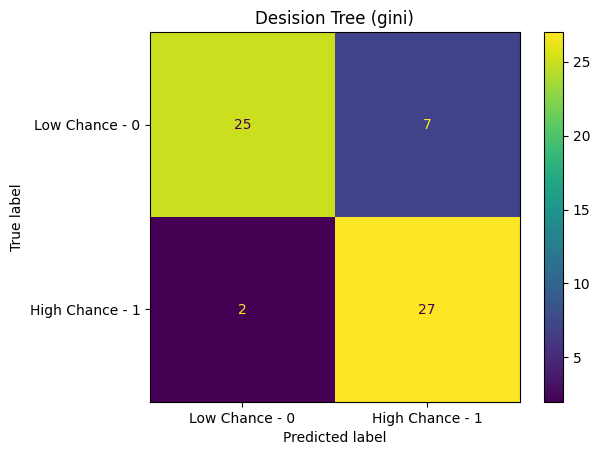

In [228]:
labels = ["Low Chance - 0", "High Chance - 1"]

tree_conf_matrix = confusion_matrix(y_test, y_pred_gini)
disp_tree = ConfusionMatrixDisplay(tree_conf_matrix,  display_labels=labels)
disp_tree.plot()
plt.title("Desision Tree (gini)")
plt.show()

here `FN = 2`

### Logostic Regression

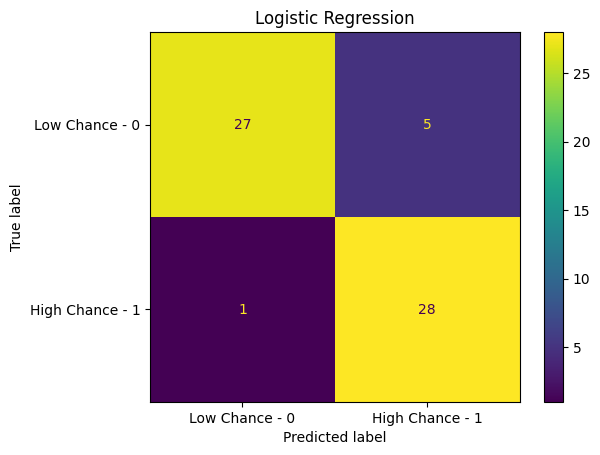

In [229]:
LR_conf_matrix = confusion_matrix(y_test_, y_hat)
disp_tree = ConfusionMatrixDisplay(LR_conf_matrix,  display_labels=labels)
disp_tree.plot()
plt.title("Logistic Regression")
plt.show()

here `FN = 1` and it is better than Decision Tree

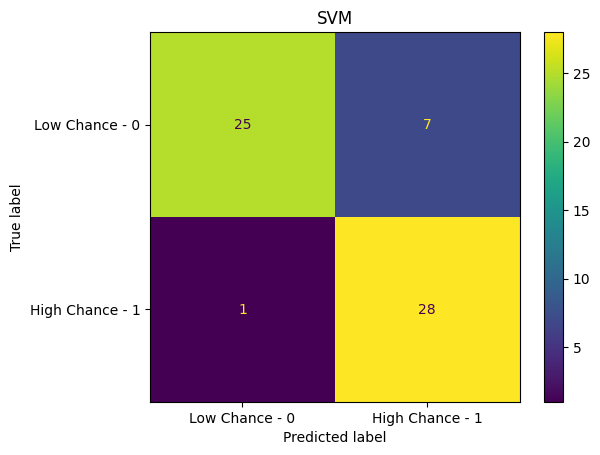

In [232]:
svm_conf_matrix = confusion_matrix(y_test, y_hat_lin)
disp_svm = ConfusionMatrixDisplay(svm_conf_matrix,  display_labels=labels)
disp_svm.plot()
plt.title("SVM")
plt.show()

here `FN = 1` ans same as Logistic Regression but has higher FP

in conclusion, `Logistic Rergression` is the best model with `accuracy = 0.90` & `f2-score = 0.87`

# Author: Sadra Gholami